# 03 · Análisis del desbalance (fase *Analyze*)

> **PRUEBA PRELIMINAR (bitácora D-09).** Se usa la ventana **2024-11 a 2026-10, 24 meses (D-06)** y valores provisionales de la franja de la mañana y del día laborable. Todas las cifras son preliminares y no deben copiarse a documentos finales.

**Pregunta central:** ¿qué estaciones se vacían o se llenan cada mañana, qué tan seguido ocurre y qué tan grande es el desbalance comparado con su capacidad?

**Cómo leer las medidas** (todas se calculan solo para días laborables, de lunes a viernes, en la franja de la mañana):

- **Saldo** = bicis que *llegan* − bicis que *salen*. Negativo: la estación pierde bicis. Positivo: las acumula.
- **Persistencia** = en qué % de los días el saldo es de 5 bicis o más (en un sentido u otro). Mide si es un hecho de todos los días o de un día aislado.
- **Presión** = saldo medio ÷ capacidad de la estación. Un valor de −2 significa que cada mañana salen el doble de bicis de las que caben.
- **Bicis necesarias** = cuántas bicis tendría que haber a las 7:00 para que la estación no se quedara vacía, si nadie la rellenara. Si es mayor que la capacidad, es **imposible** cubrirla sin rebalanceo durante la mañana. Es un **indicador indirecto**: no mide cuándo estuvo vacía de verdad, porque los viajes no traen el inventario.

In [1]:
import sys
from pathlib import Path

# Localiza la raíz del repositorio (la carpeta que contiene config/pipeline.toml) para poder importar el pipeline.
raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "pipeline.toml").exists())
sys.path.insert(0, str(raiz))

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

from pipeline import bronze, config, descarga, gold, silver

cfg = config.cargar()
pd.options.display.float_format = "{:,.1f}".format
pd.options.display.max_columns = 30
pd.options.display.width = 200
print("Ventana de datos:", cfg["ventana"]["desde"], "a", cfg["ventana"]["hasta"])

Ventana de datos: 2024-11 a 2026-10


## 1. Construir la capa *gold*

Se calculan las tablas resumidas. Después se **verifica que sus totales cuadren con un recuento directo de la capa *silver***: si no cuadran, el proceso se detiene.

In [2]:
validaciones = gold.construir_gold(cfg)
validaciones

,comprobación,gold,silver,coincide
0,salidas de la mañana: gold = recuento directo ...,7694762,7694762,True
1,llegadas de la mañana: gold = recuento directo...,7659576,7659576,True


La ventana tiene **dos periodos de 12 meses** (definidos en `config/pipeline.toml`) para poder comparar un año con el siguiente. Cada periodo cubre los mismos 12 meses del calendario, así que la estacionalidad (lluvias, vacaciones) pesa igual en los dos. Las secciones 2 a 5 describen el **periodo más reciente**; la sección 6 compara los dos.

In [3]:
a = cfg["analisis"]
p_all = pd.read_parquet(config.GOLD / "persistencia_estacion.parquet")
ph_all = pd.read_parquet(config.GOLD / "perfil_horario_estacion.parquet")
od_all = pd.read_parquet(config.GOLD / "od_corredor.parquet")
periodos = [x["nombre"] for x in cfg["periodos"]]
reciente = periodos[-1]
p, ph, od = (t[t["periodo"] == reciente] for t in (p_all, ph_all, od_all))
columnas = ["est", "nombre", "capacidad", "saldo_medio", "pct_dias_gana", "pct_dias_pierde", "presion"]
print(f"Franja de la mañana: horas {a['hora_inicio']} a {a['hora_fin']} (hasta las {a['hora_fin']}:59).")
print("Días laborables por periodo:", p_all.groupby("periodo")["dias_laborables"].max().to_dict())
print(f"Periodo que describen las secciones 2 a 5: {reciente}. Estaciones: {len(p)}.")

Franja de la mañana: horas 7 a 10 (hasta las 10:59).
Días laborables por periodo: {'2024-11 a 2025-10': 261, '2025-11 a 2026-10': 260}
Periodo que describen las secciones 2 a 5: 2025-11 a 2026-10. Estaciones: 682.


## 2. ¿Qué estaciones se vacían y cuáles se llenan?

**Estaciones que más bicis pierden cada mañana** (saldo medio más negativo):

In [4]:
p.nsmallest(10, "saldo_medio")[columnas].reset_index(drop=True)

,est,nombre,capacidad,saldo_medio,pct_dias_gana,pct_dias_pierde,presion
0,271-272,CE-271-272 Jesús García - Carlos J. Meneses,74.0,-138.9,0.0,92.3,-1.9
1,273-274,CE-273-274 Luis Donaldo Colosio - Av. Jesús Ga...,70.0,-113.1,0.4,88.1,-1.6
2,266-267,CE-266-267 Jesús García - Carlos J. Meneses,74.0,-59.5,0.4,89.2,-0.8
3,208,CE-208 Hesiodo-Lamartine,25.0,-52.9,0.0,98.1,-2.1
4,548,CE-548 Dr. Mariano Azuela - Jose Antonio Alzate,39.0,-44.0,0.8,93.8,-1.1
5,268-269,CE-268-269 Luis Donaldo Colosio - Av. Jesús Ga...,69.0,-42.8,0.0,88.5,-0.6
6,176,CE-176 Av. Jesús García-Luis Donaldo Colosio,39.0,-40.5,0.0,88.1,-1.0
7,495,CE-495 Amado Nervo - de los Maestros,39.0,-34.0,0.4,92.3,-0.9
8,547,CE-547 Dr. Enrique González Martínez - Salvado...,31.0,-33.4,0.0,87.7,-1.1
9,158-159,CE-158-159 Huatabampo-Eje 1 Pte. Av. Cuauhtémoc,74.0,-33.3,0.0,97.7,-0.5


**Estaciones que más bicis acumulan cada mañana** (saldo medio más positivo):

In [5]:
p.nlargest(10, "saldo_medio")[columnas].reset_index(drop=True)

,est,nombre,capacidad,saldo_medio,pct_dias_gana,pct_dias_pierde,presion
0,014,CE-014 Reforma - Río de Plata,39.0,117.5,98.5,0.0,3.0
1,018,CE-018 Reforma - Río Rhin,39.0,59.9,96.5,0.0,1.5
2,474,CE-474 Bahía de San Hipólito-Bahía del Espírit...,31.0,54.1,95.0,0.0,1.7
3,027,CE-027 Reforma- Havre,43.0,53.4,96.2,0.0,1.2
4,217,CE-217 Euler-Horacio,31.0,53.1,99.2,0.0,1.7
5,242,CE-242 Pról. Moliere-Miguel de Cervantes Saavedra,31.0,51.4,99.6,0.0,1.7
6,235-236,CE-235-236 Campos Elíseos-Moliere,55.0,46.1,94.6,0.0,0.8
7,017,CE-017 Reforma - Río Tiber,27.0,45.5,96.9,0.0,1.7
8,219,CE-219 Esopo-FC de Cuernavaca,39.0,42.2,95.4,0.0,1.1
9,261,CE-261 Paseo de la Reforma-Río de la Plata,43.0,41.2,94.6,0.0,1.0


## 3. El corredor Buenavista → Reforma

Las estaciones de Buenavista salen de la propuesta (`config/pipeline.toml`) y **falta confirmarlas en el mapa**. Se comparan con la estación 014 de Reforma, la que la propuesta señalaba como la más saturada.

In [6]:
clave = p[p["est"].isin(a["origenes_buenavista"] + a["estaciones_reforma"])]
clave[columnas + ["bicis_necesarias_media", "bicis_necesarias_max", "espacios_necesarios_media"]].reset_index(drop=True)

,est,nombre,capacidad,saldo_medio,pct_dias_gana,pct_dias_pierde,presion,bicis_necesarias_media,bicis_necesarias_max,espacios_necesarios_media
0,271-272,CE-271-272 Jesús García - Carlos J. Meneses,74.0,-138.9,0.0,92.3,-1.9,139.5,359.0,0.3
1,268-269,CE-268-269 Luis Donaldo Colosio - Av. Jesús Ga...,69.0,-42.8,0.0,88.5,-0.6,44.5,79.0,0.5
2,273-274,CE-273-274 Luis Donaldo Colosio - Av. Jesús Ga...,70.0,-113.1,0.4,88.1,-1.6,113.8,246.0,0.2
3,014,CE-014 Reforma - Río de Plata,39.0,117.5,98.5,0.0,3.0,0.3,4.0,118.3
4,266-267,CE-266-267 Jesús García - Carlos J. Meneses,74.0,-59.5,0.4,89.2,-0.8,60.6,233.0,0.2


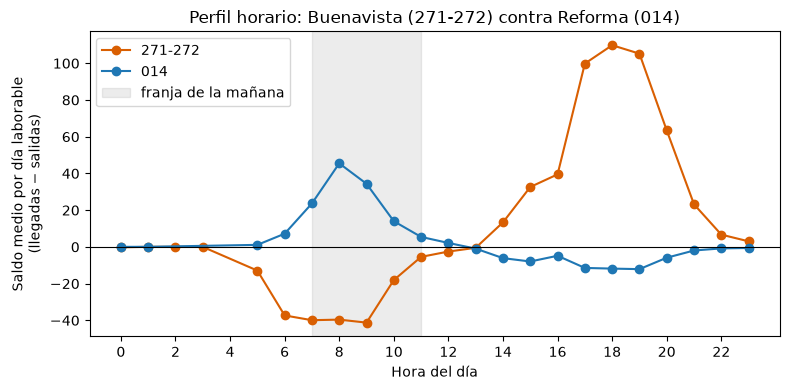

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
colores = {"271-272": "#d95f02", "014": "#1f77b4"}
for est, color in colores.items():
    d = ph[ph["est"] == est].sort_values("hora")
    ax.plot(d["hora"], d["llegadas_por_dia"] - d["salidas_por_dia"], marker="o", color=color, label=est)
ax.axvspan(a["hora_inicio"], a["hora_fin"] + 1, color="grey", alpha=0.15, label="franja de la mañana")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Hora del día")
ax.set_ylabel("Saldo medio por día laborable\n(llegadas − salidas)")
ax.set_title("Perfil horario: Buenavista (271-272) contra Reforma (014)")
ax.set_xticks(range(0, 24, 2))
ax.legend()
fig.tight_layout()
fig.savefig(config.FIGURAS / "03_perfil_horario.png", dpi=150)
plt.show()

**Cómo leer la gráfica:** por arriba de cero, la estación recibe más bicis de las que salen en esa hora; por debajo, pierde. Si la estación 271-272 se hunde por la mañana y 014 sube, y por la tarde ocurre lo contrario, el flujo es de **ida y vuelta desfasado**. Esto es un patrón observado; **no prueba por sí solo que la causa sea el transbordo del tren** (hipótesis por validar).

## 4. ¿Qué tan grande es el desbalance frente a la capacidad?

In [8]:
c = p.dropna(subset=["capacidad"])
resumen = pd.DataFrame({
    "estaciones con capacidad conocida": [len(c)],
    "con |saldo medio| mayor que su capacidad": [int((c["presion"].abs() > 1).sum())],
    "con |saldo medio| mayor que la mitad de su capacidad": [int((c["presion"].abs() > 0.5).sum())],
})
top100 = p["saldo_medio"].abs().nlargest(100).sum() / p["saldo_medio"].abs().sum()
display(resumen)
print(f"Las 100 estaciones con mayor desbalance concentran el {top100:.0%} del desbalance total (suma de |saldo medio|).")

,estaciones con capacidad conocida,con |saldo medio| mayor que su capacidad,con |saldo medio| mayor que la mitad de su capacidad
0,677,32,155


Las 100 estaciones con mayor desbalance concentran el 46% del desbalance total (suma de |saldo medio|).


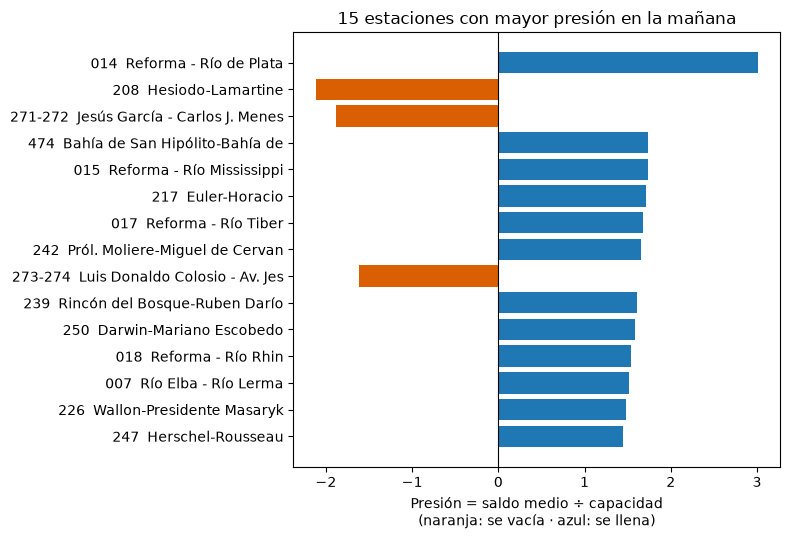

In [9]:
top = c.reindex(c["presion"].abs().sort_values(ascending=False).index).head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top["est"] + "  " + top["nombre"].str.replace(r"^CE-[\d-]+\s*", "", regex=True).str.slice(0, 30), top["presion"],
        color=["#d95f02" if v < 0 else "#1f77b4" for v in top["presion"]])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Presión = saldo medio ÷ capacidad\n(naranja: se vacía · azul: se llena)")
ax.set_title("15 estaciones con mayor presión en la mañana")
fig.tight_layout()
fig.savefig(config.FIGURAS / "03_ranking_presion.png", dpi=150)
plt.show()

## 5. Rutas más frecuentes desde Buenavista (franja de la mañana)

In [10]:
destinos = (od.groupby("destino", as_index=False)[["viajes", "viajes_por_dia"]].sum()
            .sort_values("viajes", ascending=False).head(10))
destinos.merge(pd.read_parquet(config.GOLD / "estaciones.parquet")[["codigo", "nombre"]],
               left_on="destino", right_on="codigo", how="left")[["destino", "nombre", "viajes", "viajes_por_dia"]]

,destino,nombre,viajes,viajes_por_dia
0,014,CE-014 Reforma - Río de Plata,2748,10.5
1,020,CE-020 Reforma- Río Támesis,2306,8.8
2,017,CE-017 Reforma - Río Tiber,2292,8.9
3,015,CE-015 Reforma - Río Mississippi,2243,8.6
4,010,CE-010 Reforma - Ramírez,1798,6.9
5,474,CE-474 Bahía de San Hipólito-Bahía del Espírit...,1741,6.7
6,019,CE-019 Reforma - Río Rhin,1616,6.3
7,257,CE-257 Manuel Maria Contreras-Villalongin,1611,6.2
8,016,CE-016 Reforma - Río Tiber,1604,6.1
9,018,CE-018 Reforma - Río Rhin,1493,5.7


## 6. Comparación entre periodos y con la propuesta (pregunta 4)

La propuesta (`docs/propuesta_proyecto.md`) traía cifras de una **exploración previa con IA sobre 2024–2025**. Aquí se ponen junto a lo recalculado para cada periodo de 12 meses. Conviene ver cuánto cambian antes de decidir qué usar en el documento (bitácora D-08). **Un cambio entre periodos describe qué pasó, no por qué pasó.**

In [11]:
def metricas(periodo):
    q = p_all[p_all["periodo"] == periodo]
    qc = q.dropna(subset=["capacidad"])
    return {
        "Saldo medio de la mañana, estación 014": q.loc[q["est"] == "014", "saldo_medio"].iloc[0],
        "Saldo medio de la mañana, estación 271-272": q.loc[q["est"] == "271-272", "saldo_medio"].iloc[0],
        "Estaciones con |saldo| mayor que su capacidad": int((qc["presion"].abs() > 1).sum()),
        "Estaciones con |saldo| mayor que la mitad de su capacidad": int((qc["presion"].abs() > 0.5).sum()),
        "Peso de las 100 estaciones con mayor desbalance (%)": round(100 * q["saldo_medio"].abs().nlargest(100).sum() / q["saldo_medio"].abs().sum()),
    }

propuesta = {"Saldo medio de la mañana, estación 014": 243, "Saldo medio de la mañana, estación 271-272": -250,
             "Estaciones con |saldo| mayor que su capacidad": 36,
             "Estaciones con |saldo| mayor que la mitad de su capacidad": 167,
             "Peso de las 100 estaciones con mayor desbalance (%)": 42}
comparacion = pd.DataFrame({"propuesta (2024-2025, exploración con IA)": propuesta,
                            **{f"recalculado: {nombre}": metricas(nombre) for nombre in periodos}})
comparacion.style.format("{:,.1f}")

,"propuesta (2024-2025, exploración con IA)",recalculado: 2024-11 a 2025-10,recalculado: 2025-11 a 2026-10
"Saldo medio de la mañana, estación 014",243.0,240.9,117.5
"Saldo medio de la mañana, estación 271-272",-250.0,-178.7,-138.9
Estaciones con |saldo| mayor que su capacidad,36.0,44.0,32.0
Estaciones con |saldo| mayor que la mitad de su capacidad,167.0,160.0,155.0
Peso de las 100 estaciones con mayor desbalance (%),42.0,49.0,46.0


In [12]:
clave_all = p_all[p_all["est"].isin(a["origenes_buenavista"] + a["estaciones_reforma"])]
clave_all.pivot(index="est", columns="periodo", values=["saldo_medio", "pct_dias_gana", "pct_dias_pierde", "bicis_necesarias_media"])

saldo_medio                       pct_dias_gana                     pct_dias_pierde                   bicis_necesarias_media                  
periodo 2024-11 a 2025-10 2025-11 a 2026-10 2024-11 a 2025-10 2025-11 a 2026-10 2024-11 a 2025-10 2025-11 a 2026-10      2024-11 a 2025-10 2025-11 a 2026-10
est                                                                                                                                                         
014                 240.9             117.5              98.1              98.5               0.0               0.0                    0.4               0.3
266-267             -74.5             -59.5               0.0               0.4              91.6              89.2                   75.5              60.6
268-269             -36.9             -42.8               0.0               0.0              86.6              88.5                   38.8              44.5
271-272            -178.7            -138.9               0.0               0.0              93.1              92.3                  179.1             139.5
273-274            -162.3            -113.1               0.8               0.4              90.4              88.1                  163.0             113.8

## 7. Limitaciones y qué sigue

- **Sin inventario:** los viajes muestran flujos, no estaciones vacías. La medida de *bicis necesarias* es indirecta, e ignora el rebalanceo que hace el operador (esos movimientos no aparecen en los viajes).
- **Capacidad actual:** el catálogo trae la capacidad de hoy (2026-11-20), no la de 2024–2026; si cambió, la presión se mide con una capacidad distinta de la real.
- **Correlación no es causalidad:** el patrón es compatible con la hipótesis del transbordo en Buenavista, pero no la demuestra. Tampoco se sabe aún *por qué* cambia de un periodo a otro.
- **Día laborable:** solo lunes a viernes; los festivos no se excluyen (P-08). La franja de 7 a 10 h es provisional (P-10).
- **Pendientes:** confirmar que las 4 estaciones de Buenavista son las correctas y revisar la cifra de "~580 viajes diarios" de la propuesta (D-10).

**Siguiente paso:** `04_visualizaciones.ipynb` (versión final de las gráficas).